# Perfiles de salud por país con PCA y DBSCAN

**Materia:** Inteligencia Artificial — Aprendizaje No Supervisado
**Alumno:** Camilo Tonatiuh Guzman Arias · Registro 4949514 · Ing. Mecatrónica
**Universidad Autónoma de Guadalajara (UAG)**

**Objetivo.** Agrupar a los países del mundo según su perfil de salud usando datos reales del Banco Mundial (descargados por API), sin etiquetas previas:

1. Descargar y limpiar 11 indicadores de salud.
2. Transformar (logaritmo) y escalar (StandardScaler) las variables.
3. Reducir dimensiones con **PCA** para obtener un "mapa" de 2 ejes.
4. Encontrar grupos con **DBSCAN** sobre ese mapa y describir el perfil de cada grupo.

## 1. Librerías

In [1]:
# Importando librerías
import requests                      # para "hablar" con la API por internet
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

## 2. Conexión con la API del Banco Mundial

Primero hacemos una consulta de prueba: la esperanza de vida de México. Si no hay internet, el notebook usa el respaldo `datos_salud_banco_mundial.csv` que se genera más abajo.

In [2]:
URL_BASE = "https://api.worldbank.org/v2"
ARCHIVO_RESPALDO = "datos_salud_banco_mundial.csv"

try:
    url = f"{URL_BASE}/country/MEX/indicator/SP.DYN.LE00.IN"
    respuesta = requests.get(url, params={"format": "json", "mrnev": 1}, timeout=30)
    respuesta.raise_for_status()
    API_OK = True
    print("Código de estado:", respuesta.status_code)
except Exception as error:
    API_OK = False
    print("No se pudo conectar con la API → se usará el respaldo", ARCHIVO_RESPALDO)

No se pudo conectar con la API → se usará el respaldo datos_salud_banco_mundial.csv


In [3]:
# La API responde una lista: [metadatos, registros]
if API_OK:
    metadatos, registros = respuesta.json()
    print("Indicador:", registros[0]["indicator"]["value"])
    print("País:", registros[0]["country"]["value"], "| Año:", registros[0]["date"], "| Valor:", registros[0]["value"])

### 2.1 Catálogo de países

El catálogo trae países **y agregados** (regiones, grupos de ingreso). Los agregados tienen `region.id = "NA"` y se descartan.

In [4]:
nombres_region = {
    "EAS": "Asia Oriental y Pacífico",
    "ECS": "Europa y Asia Central",
    "LCN": "América Latina y Caribe",
    "MEA": "Medio Oriente, N. África, Afganistán y Pakistán",
    "NAC": "Norteamérica",
    "SAS": "Asia del Sur",
    "SSF": "África Subsahariana",
}
nombres_ingreso = {"HIC": "Alto", "UMC": "Medio-alto", "LMC": "Medio-bajo", "LIC": "Bajo", "INX": "Sin clasificar"}

if API_OK:
    respuesta = requests.get(f"{URL_BASE}/es/country", params={"format": "json", "per_page": 500}, timeout=60)
    metadatos, registros = respuesta.json()
    catalogo = pd.json_normalize(registros)                 # "aplana" el JSON anidado en columnas
    print("Economías en el catálogo:", len(catalogo))

    paises = catalogo[catalogo["region.id"] != "NA"].copy()  # .copy() evita el SettingWithCopyWarning
    paises["region"] = paises["region.id"].map(nombres_region).fillna(paises["region.value"].str.strip())
    paises["ingreso"] = paises["incomeLevel.id"].map(nombres_ingreso).fillna(paises["incomeLevel.value"].str.strip())
    paises = paises.rename(columns={"id": "iso3", "name": "pais"})[["iso3", "pais", "region", "ingreso"]]
else:
    paises = pd.read_csv(ARCHIVO_RESPALDO)[["iso3", "pais", "region", "ingreso"]]

print("Países reales:", len(paises))
paises["region"].value_counts()

Países reales: 217


region
Europa y Asia Central                              58
África Subsahariana                                48
América Latina y Caribe                            42
Asia Oriental y Pacífico                           37
Medio Oriente, N. África, Afganistán y Pakistán    23
Asia del Sur                                        6
Norteamérica                                        3
Name: count, dtype: int64

### 2.2 Indicadores de salud

Elegimos 11 indicadores en tres bloques: **resultados**, **recursos y acceso** y **carga de enfermedad**.

In [5]:
indicadores = {
    # Resultados en salud
    "SP.DYN.LE00.IN":    "Esperanza de vida",           # años
    "SH.DYN.MORT":       "Mortalidad <5 años",          # muertes por 1,000 nacidos vivos
    "SH.STA.MMRT":       "Mortalidad materna",          # muertes por 100,000 nacidos vivos
    # Recursos y acceso
    "SH.XPD.CHEX.GD.ZS": "Gasto en salud (% PIB)",      # gasto corriente en salud
    "SH.XPD.OOPC.CH.ZS": "Gasto de bolsillo (%)",       # % del gasto en salud que paga el paciente
    "SH.MED.PHYS.ZS":    "Médicos x 1,000 hab.",
    "SH.MED.BEDS.ZS":    "Camas x 1,000 hab.",
    "SH.IMM.IDPT":       "Vacuna DPT (%)",              # % de niños de 12-23 meses vacunados
    # Carga de enfermedad
    "SH.TBS.INCD":       "Tuberculosis x 100,000",      # casos nuevos por año
    "SH.DYN.NCOM.ZS":    "Muerte por ENT 30-70 (%)",    # cardiovascular, cáncer, diabetes, respiratoria
    "SH.STA.DIAB.ZS":    "Diabetes (%)",                # % de adultos de 20 a 79 años
}
print(len(indicadores), "indicadores")

11 indicadores


In [6]:
def descargar_indicador(codigo, fuente=16):
    url = f"{URL_BASE}/country/all/indicator/{codigo}"
    parametros = {"format": "json", "source": fuente, "mrnev": 1, "per_page": 500}
    datos_json = requests.get(url, params=parametros, timeout=60).json()

    # Si la API respondió con un error o sin registros...
    if len(datos_json) < 2 or not datos_json[1]:
        if fuente == 16:
            return descargar_indicador(codigo, fuente=2)    # ...plan B: misma serie en la base WDI
        print(f"⚠️ {codigo}: la API no devolvió datos")
        return pd.DataFrame(columns=["iso3", "anio", "valor"])

    tabla = pd.DataFrame(datos_json[1])[["countryiso3code", "date", "value"]]
    tabla.columns = ["iso3", "anio", "valor"]
    tabla["anio"] = tabla["anio"].astype(int)
    tabla["valor"] = tabla["valor"].astype(float)
    return tabla

### 2.3 Descarga y armado de la tabla

Se usa el **dato más reciente** de cada país (`mrnev=1`). Valores anteriores a 2015 se consideran obsoletos y se vuelven `NaN`. Luego se pasa de formato "largo" a "ancho": una fila por país y una columna por indicador.

In [7]:
ANIO_MINIMO = 2015

if API_OK:
    tablas = []
    for codigo, nombre in indicadores.items():
        tabla = descargar_indicador(codigo)
        if tabla.empty:
            continue
        tabla["indicador"] = nombre
        tablas.append(tabla)
        print(f"✓ {nombre:<26} {tabla['valor'].notna().sum():>4} economías con dato")

    largo = pd.concat(tablas, ignore_index=True)
    largo = largo[largo["iso3"].isin(paises["iso3"])].copy()      # solo países reales
    largo.loc[largo["anio"] < ANIO_MINIMO, "valor"] = np.nan

    valores = largo.pivot(index="iso3", columns="indicador", values="valor")
    datos = paises.set_index("iso3").join(valores)
    columnas_ind = [n for n in indicadores.values() if n in datos.columns]
    datos = datos[["pais", "region", "ingreso"] + columnas_ind]
    datos.to_csv(ARCHIVO_RESPALDO)                                 # respaldo por si la API falla después
else:
    datos = pd.read_csv(ARCHIVO_RESPALDO, index_col="iso3")
    columnas_ind = [n for n in indicadores.values() if n in datos.columns]

print("Tabla final:", datos.shape[0], "países ×", len(columnas_ind), "indicadores")
datos.head()

Tabla final: 217 países × 11 indicadores


,pais,region,ingreso,Esperanza de vida,Mortalidad <5 años,Mortalidad materna,Gasto en salud (% PIB),Gasto de bolsillo (%),"Médicos x 1,000 hab.","Camas x 1,000 hab.",Vacuna DPT (%),"Tuberculosis x 100,000",Muerte por ENT 30-70 (%),Diabetes (%)
iso3,,,,,,,,,,,,,,
ABW,Aruba,América Latina y Caribe,Alto,76.500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.3,NaN,4.6
AFG,Afganistán,"Medio Oriente, N. África, Afganistán y Pakistán",Bajo,66.289,53.0,521.0,14.985763,77.139587,0.317,0.35,59.0,203.0,32.7,11.7
AGO,Angola,África Subsahariana,Medio-bajo,64.805,49.0,183.0,2.546929,32.546677,0.244,0.75,64.0,373.0,24.7,4.9
ALB,Albania,Europa y Asia Central,Medio-alto,79.776,9.2,7.0,7.052403,48.274628,1.879,2.90,97.0,15.0,10.0,10.6
AND,Andorra,Europa y Asia Central,Alto,84.188,2.5,11.0,7.699280,11.145945,5.068,NaN,98.0,4.9,NaN,10.1


## 3. Calidad de los datos

Un indicador con muchos huecos obligaría a descartar demasiados países. Conservamos solo los que tienen dato en **al menos 80 %** de los países.

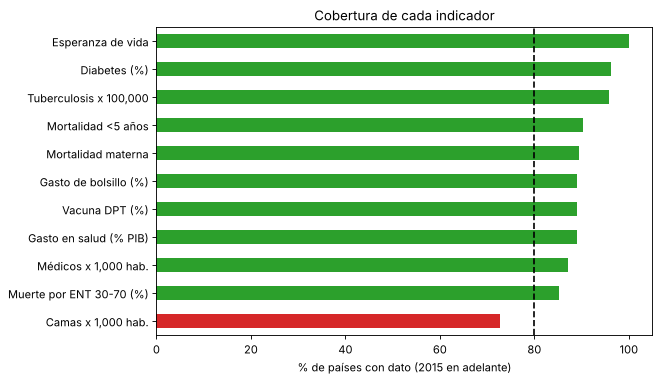

In [8]:
# Qué tan completos vienen los datos (en %)
cobertura = datos[columnas_ind].notna().mean().sort_values() * 100

UMBRAL = 80      # % mínimo de países con dato para conservar un indicador
colores = ["tab:green" if c >= UMBRAL else "tab:red" for c in cobertura]

ax = cobertura.plot(kind="barh", color=colores, figsize=(8, 5))
ax.axvline(UMBRAL, color="black", linestyle="--")
ax.set_xlabel(f"% de países con dato ({ANIO_MINIMO} en adelante)")
ax.set_title("Cobertura de cada indicador")
plt.show()

In [9]:
columnas = [c for c in columnas_ind if cobertura[c] >= UMBRAL]
print("Conservamos:", columnas)
print("Descartamos:", [c for c in columnas_ind if cobertura[c] < UMBRAL])

completos = datos.dropna(subset=columnas)
print(f"\nPaíses con TODOS los indicadores conservados: {len(completos)} de {len(datos)}")

Conservamos: ['Esperanza de vida', 'Mortalidad <5 años', 'Mortalidad materna', 'Gasto en salud (% PIB)', 'Gasto de bolsillo (%)', 'Médicos x 1,000 hab.', 'Vacuna DPT (%)', 'Tuberculosis x 100,000', 'Muerte por ENT 30-70 (%)', 'Diabetes (%)']
Descartamos: ['Camas x 1,000 hab.']

Países con TODOS los indicadores conservados: 180 de 217


In [10]:
# ¿De qué regiones son los países que dejamos fuera?
pd.DataFrame({"antes": datos["region"].value_counts(),
              "después": completos["region"].value_counts()})

,antes,después
region,,
Europa y Asia Central,58,48
África Subsahariana,48,47
América Latina y Caribe,42,30
Asia Oriental y Pacífico,37,24
"Medio Oriente, N. África, Afganistán y Pakistán",23,23
Asia del Sur,6,6
Norteamérica,3,2


Los países que se pierden son, sobre todo, territorios pequeños (islas del Caribe, Pacífico y microestados europeos) que no reportan varios indicadores. Las regiones grandes quedan bien representadas.

## 4. Transformación de los datos

PCA y DBSCAN trabajan con distancias, así que variables muy **sesgadas** (pocos países con valores enormes) dominarían el análisis. Medimos el sesgo y aplicamos `log(1 + x)` a las variables con sesgo > 1.

In [11]:
X = completos[columnas]
sesgo = X.skew().sort_values(ascending=False)
sesgo.round(2)

Mortalidad materna          2.33
Tuberculosis x 100,000      1.93
Mortalidad <5 años          1.53
Diabetes (%)                1.33
Médicos x 1,000 hab.        0.83
Gasto de bolsillo (%)       0.60
Gasto en salud (% PIB)      0.56
Muerte por ENT 30-70 (%)    0.54
Esperanza de vida          -0.38
Vacuna DPT (%)             -1.45
dtype: float64

In [12]:
columnas_log = sesgo[sesgo > 1].index.tolist()        # regla práctica: sesgo > 1 = muy sesgada
print("Aplicamos logaritmo a:", columnas_log)

X_trans = X.copy()
X_trans[columnas_log] = np.log1p(X_trans[columnas_log])   # log(1 + x): funciona aunque haya ceros

Aplicamos logaritmo a: ['Mortalidad materna', 'Tuberculosis x 100,000', 'Mortalidad <5 años', 'Diabetes (%)']


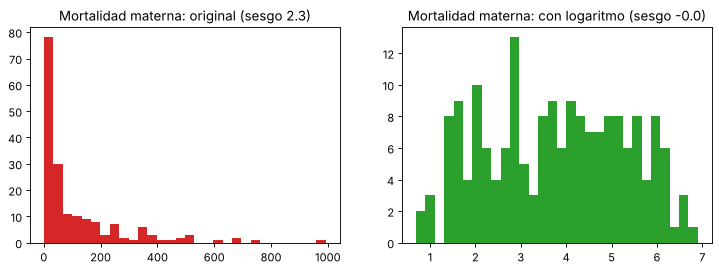

In [13]:
var = sesgo.index[0]          # la variable MÁS sesgada
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
ejes[0].hist(X[var], bins=30, color="tab:red")
ejes[0].set_title(f"{var}: original (sesgo {X[var].skew():.1f})")
ejes[1].hist(X_trans[var], bins=30, color="tab:green")
ejes[1].set_title(f"{var}: con logaritmo (sesgo {X_trans[var].skew():.1f})")
plt.show()

## 5. Escalado con StandardScaler

Los indicadores tienen unidades muy distintas (años, %, casos por 100,000). El escalado deja cada columna con **media 0 y desviación estándar 1**, para que todas pesen igual.

In [14]:
escalador = StandardScaler()
X_esc = escalador.fit_transform(X_trans)

print("Forma:", X_esc.shape, "→ (países, indicadores)")
print("Medias:      ", X_esc.mean(axis=0).round(2))
print("Desv. están.:", X_esc.std(axis=0).round(2))

Forma: (180, 10) → (países, indicadores)
Medias:       [-0. -0.  0. -0.  0. -0.  0. -0.  0.  0.]
Desv. están.: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 6. PCA

### 6.1 Intuición con dos variables

Tomamos el par de indicadores **más correlacionados**. PCA rota los ejes: el CP1 apunta hacia donde los datos más varían y el CP2 es perpendicular.

Par más correlacionado: Esperanza de vida y Mortalidad <5 años (|r| = 0.92)


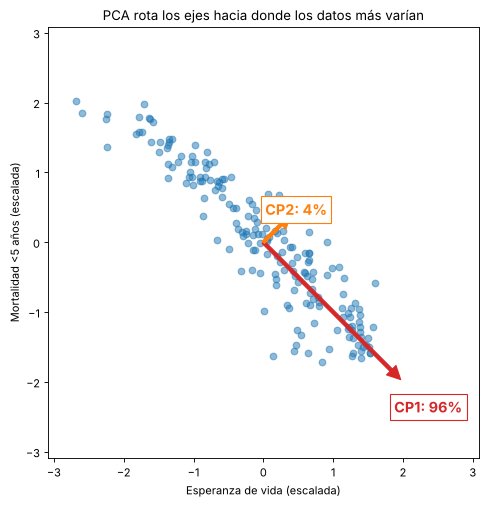

In [15]:
matriz = X_trans.corr().abs().to_numpy(copy=True)
np.fill_diagonal(matriz, 0)
i, j = np.unravel_index(matriz.argmax(), matriz.shape)
var_a, var_b = columnas[i], columnas[j]
print(f"Par más correlacionado: {var_a} y {var_b} (|r| = {matriz[i, j]:.2f})")

dos = X_esc[:, [i, j]]
pca_2 = PCA().fit(dos)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(dos[:, 0], dos[:, 1], alpha=0.5)
for k, color in zip([0, 1], ["tab:red", "tab:orange"]):
    flecha = pca_2.components_[k] * 2 * np.sqrt(pca_2.explained_variance_[k])   # largo = 2 desv. estándar
    ax.annotate("", xy=flecha, xytext=(0, 0), arrowprops=dict(color=color, width=3), annotation_clip=False)
    x, y = flecha * 1.2
    ax.text(x, y, f"CP{k+1}: {pca_2.explained_variance_ratio_[k]:.0%}", color=color, fontsize=13,
            fontweight="bold", ha="center", va="center", bbox=dict(facecolor="white", edgecolor=color))
limite = np.abs(dos).max() * 1.15
ax.set_xlim(-limite, limite)
ax.set_ylim(-limite, limite)
ax.set_xlabel(f"{var_a} (escalada)")
ax.set_ylabel(f"{var_b} (escalada)")
ax.set_aspect("equal")
ax.set_title("PCA rota los ejes hacia donde los datos más varían")
plt.show()

### 6.2 PCA con todos los indicadores

In [16]:
pca = PCA()
componentes = pca.fit_transform(X_esc)

varianza = pca.explained_variance_ratio_ * 100
acumulada = varianza.cumsum()
for k in range(len(varianza)):
    print(f"CP{k+1}: {varianza[k]:5.1f} %    acumulada: {acumulada[k]:5.1f} %")

CP1:  53.6 %    acumulada:  53.6 %
CP2:  11.4 %    acumulada:  65.1 %
CP3:   8.7 %    acumulada:  73.8 %
CP4:   8.0 %    acumulada:  81.8 %
CP5:   6.1 %    acumulada:  87.8 %
CP6:   4.7 %    acumulada:  92.6 %
CP7:   3.5 %    acumulada:  96.1 %
CP8:   2.5 %    acumulada:  98.6 %
CP9:   0.9 %    acumulada:  99.5 %
CP10:   0.5 %    acumulada: 100.0 %


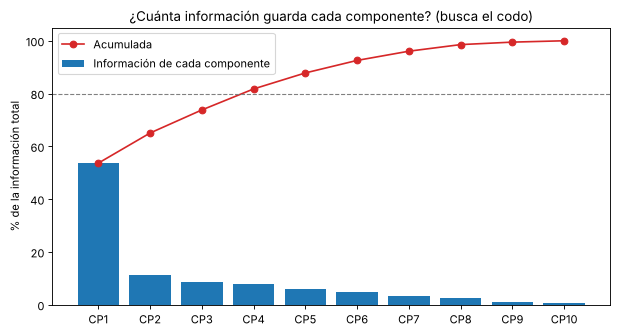

In [17]:
nombres_cp = [f"CP{k+1}" for k in range(len(varianza))]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(nombres_cp, varianza, color="tab:blue", label="Información de cada componente")
ax.plot(nombres_cp, acumulada, color="tab:red", marker="o", label="Acumulada")
ax.axhline(80, color="gray", linestyle="--", linewidth=1)
ax.set_ylabel("% de la información total")
ax.set_title("¿Cuánta información guarda cada componente? (busca el codo)")
ax.legend()
plt.show()

**Interpretación.** El CP1 por sí solo concentra **53.6 %** de la información y el CP2 otro **11.4 %**: con solo 2 ejes conservamos ~65 % de lo que dicen los 10 indicadores. Después del CP2 la caída es suave (codo), así que usar el plano CP1–CP2 es un buen resumen para visualizar y agrupar. Para llegar a 80 % harían falta 4 componentes.

### 6.3 Cargas: ¿qué significa cada componente?

Las cargas dicen cuánto pesa cada indicador en cada componente. Se orienta el CP1 para que **más a la derecha = más esperanza de vida** (el signo de PCA es arbitrario).

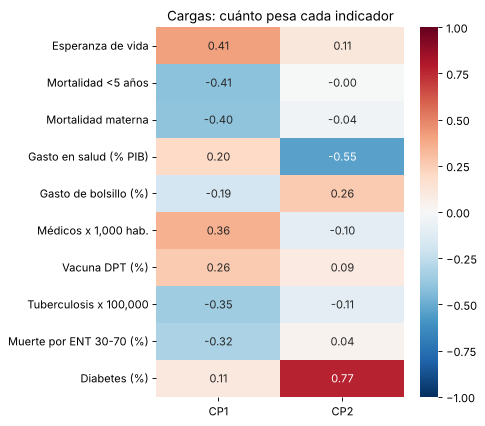

In [18]:
cargas = pd.DataFrame(pca.components_[:2].T, index=columnas, columns=["CP1", "CP2"])

if "Esperanza de vida" in cargas.index and cargas.loc["Esperanza de vida", "CP1"] < 0:
    cargas["CP1"] = -cargas["CP1"]
    componentes[:, 0] = -componentes[:, 0]

plt.figure(figsize=(5, 6))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Cargas: cuánto pesa cada indicador")
plt.show()

**Interpretación de los ejes.**

- **CP1 = nivel general de salud y desarrollo.** Pesa positivo en esperanza de vida (0.41), médicos (0.36) y vacunación (0.26), y negativo en mortalidad infantil (−0.41), mortalidad materna (−0.40), tuberculosis (−0.35) y muertes por enfermedades no transmisibles (−0.32). A la derecha están los países con mejores sistemas de salud; a la izquierda, los más rezagados.
- **CP2 = diabetes vs. gasto en salud.** Lo domina la diabetes (+0.77) frente al gasto en salud como % del PIB (−0.55). Arriba quedan países con mucha diabetes y poco gasto relativo (p. ej. el Golfo Pérsico y el sur de Asia); abajo, países que gastan mucho en salud con poca diabetes.

### 6.4 Mapa de países en el plano PCA

In [19]:
mapa = completos[["pais", "region", "ingreso"]].copy()
mapa["CP1"] = componentes[:, 0]
mapa["CP2"] = componentes[:, 1]

regiones = sorted(mapa["region"].unique())
MARCADORES = dict(zip(regiones, ["o", "s", "^", "D", "v", "P", "X", "*", "h"]))
COLORES_REGION = dict(zip(regiones, plt.cm.tab10.colors))

# Países que etiquetamos para orientarnos (solo si quedaron en los datos)
PAISES_GUIA = ["MEX", "USA", "CAN", "BRA", "ARG", "CHL", "CUB", "HTI", "ESP", "DEU", "RUS",
               "CHN", "JPN", "IND", "NGA", "ZAF", "EGY", "SAU", "AUS"]

def etiquetar(ax, tabla, lista_iso3, tamano=8, color="black"):
    for iso3 in lista_iso3:
        if iso3 in tabla.index:
            ax.annotate(tabla.loc[iso3, "pais"], (tabla.loc[iso3, "CP1"], tabla.loc[iso3, "CP2"]),
                        fontsize=tamano, color=color, xytext=(4, 4), textcoords="offset points")

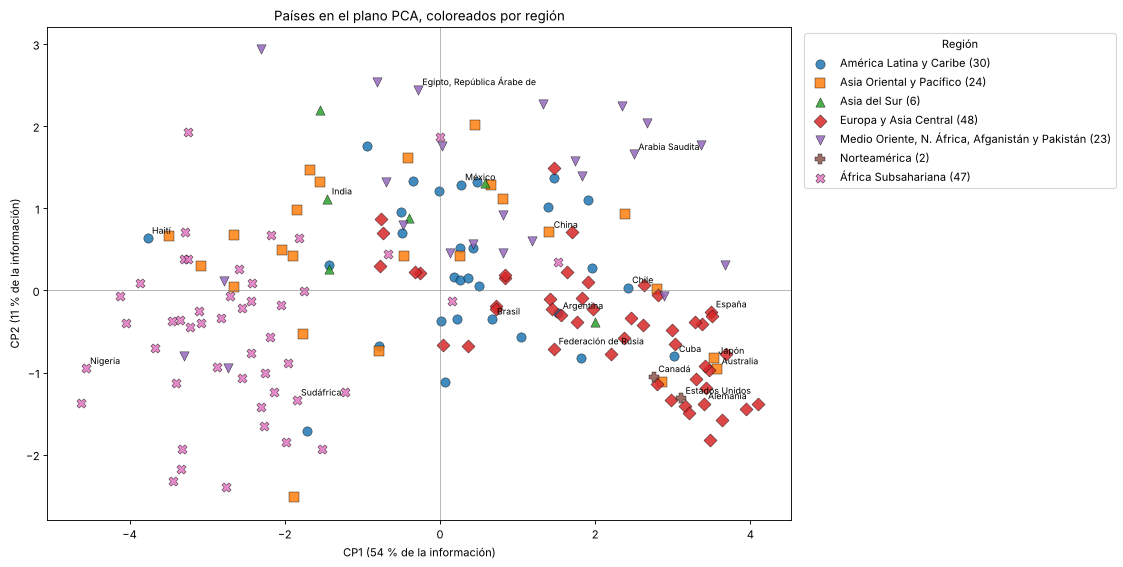

In [20]:
fig, ax = plt.subplots(figsize=(12, 8))
for region in regiones:
    sub = mapa[mapa["region"] == region]
    ax.scatter(sub["CP1"], sub["CP2"], label=f"{region} ({len(sub)})", marker=MARCADORES[region],
               color=COLORES_REGION[region], s=70, edgecolor="black", linewidth=0.4, alpha=0.85)
etiquetar(ax, mapa, PAISES_GUIA)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)
ax.set_xlabel(f"CP1 ({varianza[0]:.0f} % de la información)")
ax.set_ylabel(f"CP2 ({varianza[1]:.0f} % de la información)")
ax.set_title("Países en el plano PCA, coloreados por región")
ax.legend(title="Región", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

### 6.5 Biplot: países + dirección de cada indicador

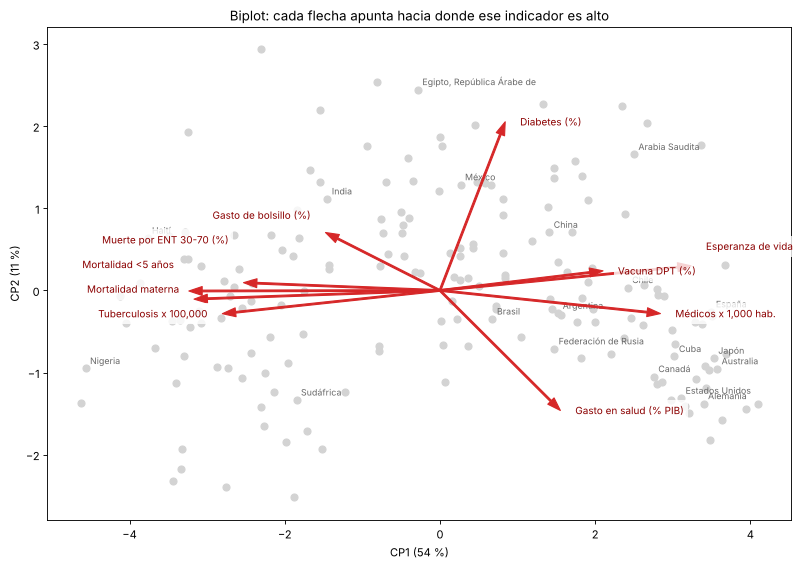

In [21]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(mapa["CP1"], mapa["CP2"], color="lightgray", s=40)
etiquetar(ax, mapa, PAISES_GUIA, color="dimgray")

# Estiramos las flechas para que llenen el mapa (cada eje por separado): lo que importa es la DIRECCIÓN
escala_x = 0.7 * mapa["CP1"].abs().max() / cargas["CP1"].abs().max()
escala_y = 0.7 * mapa["CP2"].abs().max() / cargas["CP2"].abs().max()
puntas = []
for variable in cargas.index:
    x = cargas.loc[variable, "CP1"] * escala_x
    y = cargas.loc[variable, "CP2"] * escala_y
    ax.annotate("", xy=(x, y), xytext=(0, 0), arrowprops=dict(color="tab:red", width=1.5, headwidth=8))
    puntas.append([x, y, variable])

# Si dos etiquetas quedan encimadas (flechas casi paralelas), separamos la de arriba
alto = 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])
ancho = 0.25 * (ax.get_xlim()[1] - ax.get_xlim()[0])
puntas.sort(key=lambda p: p[1])
for k in range(1, len(puntas)):
    for previa in puntas[:k]:
        if abs(puntas[k][0] - previa[0]) < ancho and abs(puntas[k][1] - previa[1]) < alto:
            puntas[k][1] = previa[1] + alto
separacion = 0.02 * (ax.get_xlim()[1] - ax.get_xlim()[0])
for x, y, variable in puntas:
    lado = 1 if x >= 0 else -1          # etiqueta hacia afuera de la flecha
    ax.text(x + lado * separacion, y, variable, color="darkred", fontsize=9, va="center",
            ha="left" if lado == 1 else "right", bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
ax.set_xlabel(f"CP1 ({varianza[0]:.0f} %)")
ax.set_ylabel(f"CP2 ({varianza[1]:.0f} %)")
ax.set_title("Biplot: cada flecha apunta hacia donde ese indicador es alto")
plt.show()

## 7. DBSCAN

DBSCAN agrupa por **densidad**: un país es *núcleo* si tiene al menos `min_samples` países (incluido él) dentro de un radio `eps`; los países alcanzables desde un núcleo son *borde*, y los demás son *ruido*. No hay que fijar el número de clusters de antemano.

### 7.1 Elección de `eps` con la gráfica k-distancia

Ordenamos la distancia de cada país a su 4.º vecino más cercano. El **codo** de la curva separa a los países en zonas densas de los "solitarios".

eps sugerido por el codo: 0.56


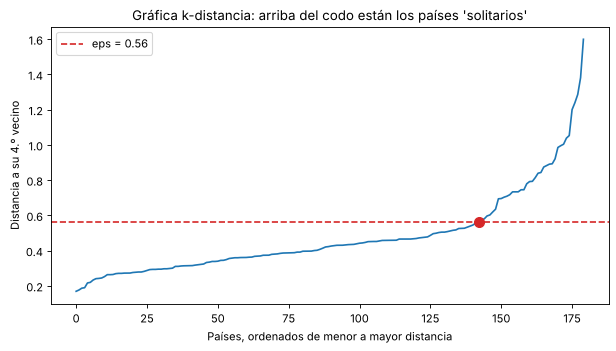

In [22]:
coords = mapa[["CP1", "CP2"]].to_numpy()
MIN_SAMPLES = 5

vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(coords)
distancias, _ = vecinos.kneighbors(coords)
# Columna 0 = el propio país (distancia 0). La última = su 4.º vecino más cercano
dist_k = np.sort(distancias[:, -1])

# Codo: el punto más alejado de la diagonal (curva normalizada a [0, 1])
x = np.linspace(0, 1, len(dist_k))
y = (dist_k - dist_k.min()) / (dist_k.max() - dist_k.min())
codo = np.argmax(x - y)
EPS = round(float(dist_k[codo]), 2)
print("eps sugerido por el codo:", EPS)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(dist_k, color="tab:blue")
ax.axhline(EPS, color="tab:red", linestyle="--", label=f"eps = {EPS}")
ax.scatter(codo, dist_k[codo], color="tab:red", s=80, zorder=3)
ax.set_xlabel("Países, ordenados de menor a mayor distancia")
ax.set_ylabel(f"Distancia a su {MIN_SAMPLES - 1}.º vecino")
ax.set_title("Gráfica k-distancia: arriba del codo están los países 'solitarios'")
ax.legend()
plt.show()

### 7.2 Entrenamiento del modelo

In [23]:
modelo = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
mapa["cluster"] = modelo.fit_predict(coords)

# Nombre legible para cada etiqueta: -1 es ruido
mapa["grupo"] = mapa["cluster"].map(lambda c: "Ruido" if c == -1 else f"Cluster {c}")

n_clusters = mapa.loc[mapa["cluster"] != -1, "cluster"].nunique()
n_ruido = (mapa["cluster"] == -1).sum()
print(f"DBSCAN encontró {n_clusters} cluster(s) y {n_ruido} país(es) como ruido")
mapa["grupo"].value_counts()

DBSCAN encontró 2 cluster(s) y 22 país(es) como ruido


grupo
Cluster 1    106
Cluster 0     52
Ruido         22
Name: count, dtype: int64

### 7.3 ¿Cómo decide DBSCAN? Núcleo, borde y ruido

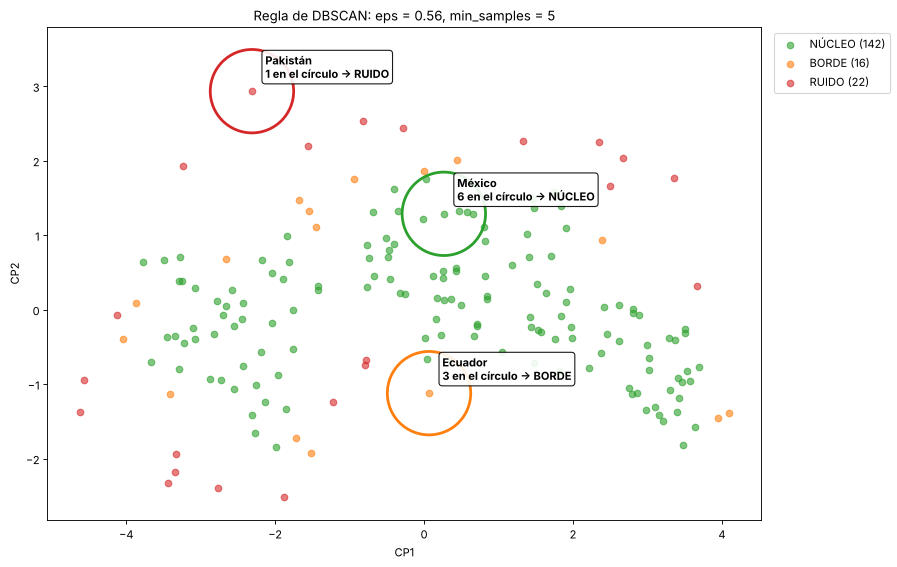

In [24]:
def contar_en_circulo(i):
    # Países (incluido él mismo) a distancia <= eps
    return int((np.linalg.norm(coords - coords[i], axis=1) <= EPS).sum())

es_nucleo = np.zeros(len(mapa), dtype=bool)
es_nucleo[modelo.core_sample_indices_] = True
tipo = np.where(es_nucleo, "NÚCLEO", np.where(mapa["cluster"] == -1, "RUIDO", "BORDE"))

# Ejemplos: México (si está) + un país de cada tipo que falte
ejemplos = [mapa.index.get_loc("MEX")] if "MEX" in mapa.index else []
for t in ["NÚCLEO", "BORDE", "RUIDO"]:
    candidatos = np.where(tipo == t)[0]
    if len(candidatos) > 0 and t not in [tipo[e] for e in ejemplos]:
        # el más aislado de su tipo, para que el círculo se vea claro
        ejemplos.append(candidatos[np.argmax(distancias[candidatos, -1])])

colores_tipo = {"NÚCLEO": "tab:green", "BORDE": "tab:orange", "RUIDO": "tab:red"}
fig, ax = plt.subplots(figsize=(13, 8))
for t, color in colores_tipo.items():
    marca = tipo == t
    ax.scatter(coords[marca, 0], coords[marca, 1], color=color, s=35, alpha=0.6, label=f"{t} ({marca.sum()})")
for i in ejemplos:
    ax.add_patch(plt.Circle(coords[i], EPS, color=colores_tipo[tipo[i]], fill=False, linewidth=2.5))
    ax.annotate(f"{mapa['pais'].iloc[i]}\n{contar_en_circulo(i)} en el círculo → {tipo[i]}",
                coords[i], xytext=(12, 12), textcoords="offset points", fontsize=10, fontweight="bold",
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.9))
ax.set_aspect("equal")
ax.set_xlabel("CP1")
ax.set_ylabel("CP2")
ax.set_title(f"Regla de DBSCAN: eps = {EPS}, min_samples = {MIN_SAMPLES}")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

### 7.4 Clusters sobre el mapa PCA

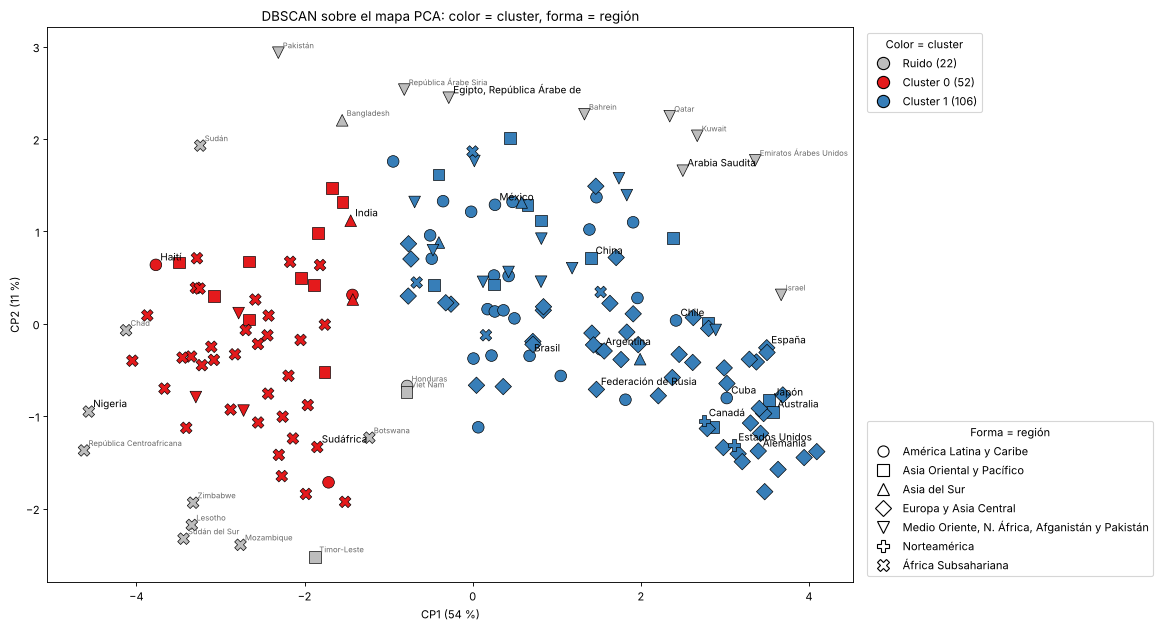

In [25]:
from matplotlib.lines import Line2D

PALETA = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628", "#f781bf", "#17becf", "#bcbd22"]

def color_de(cluster):
    return "#bdbdbd" if cluster == -1 else PALETA[cluster % len(PALETA)]

def leyenda_clusters(tabla):
    return [Line2D([], [], marker="o", linestyle="", markersize=11, markeredgecolor="black",
                   markerfacecolor=color_de(c), label=f"{g} ({n})")
            for (c, g), n in tabla.groupby(["cluster", "grupo"]).size().items()]

fig, ax = plt.subplots(figsize=(13, 9))
for region in regiones:
    sub = mapa[mapa["region"] == region]
    ax.scatter(sub["CP1"], sub["CP2"], c=[color_de(c) for c in sub["cluster"]],
               marker=MARCADORES[region], s=110, edgecolor="black", linewidth=0.6)
etiquetar(ax, mapa, PAISES_GUIA, tamano=9)
etiquetar(ax, mapa, mapa.index[mapa["cluster"] == -1].difference(PAISES_GUIA), tamano=7, color="dimgray")

leyenda_formas = [Line2D([], [], marker=MARCADORES[r], linestyle="", markersize=10, markeredgecolor="black",
                         markerfacecolor="white", label=r) for r in regiones]
primera = ax.legend(handles=leyenda_clusters(mapa), title="Color = cluster", loc="upper left", bbox_to_anchor=(1.01, 1))
ax.add_artist(primera)
ax.legend(handles=leyenda_formas, title="Forma = región", loc="lower left", bbox_to_anchor=(1.01, 0))
ax.set_xlabel(f"CP1 ({varianza[0]:.0f} %)")
ax.set_ylabel(f"CP2 ({varianza[1]:.0f} %)")
ax.set_title("DBSCAN sobre el mapa PCA: color = cluster, forma = región")
plt.show()

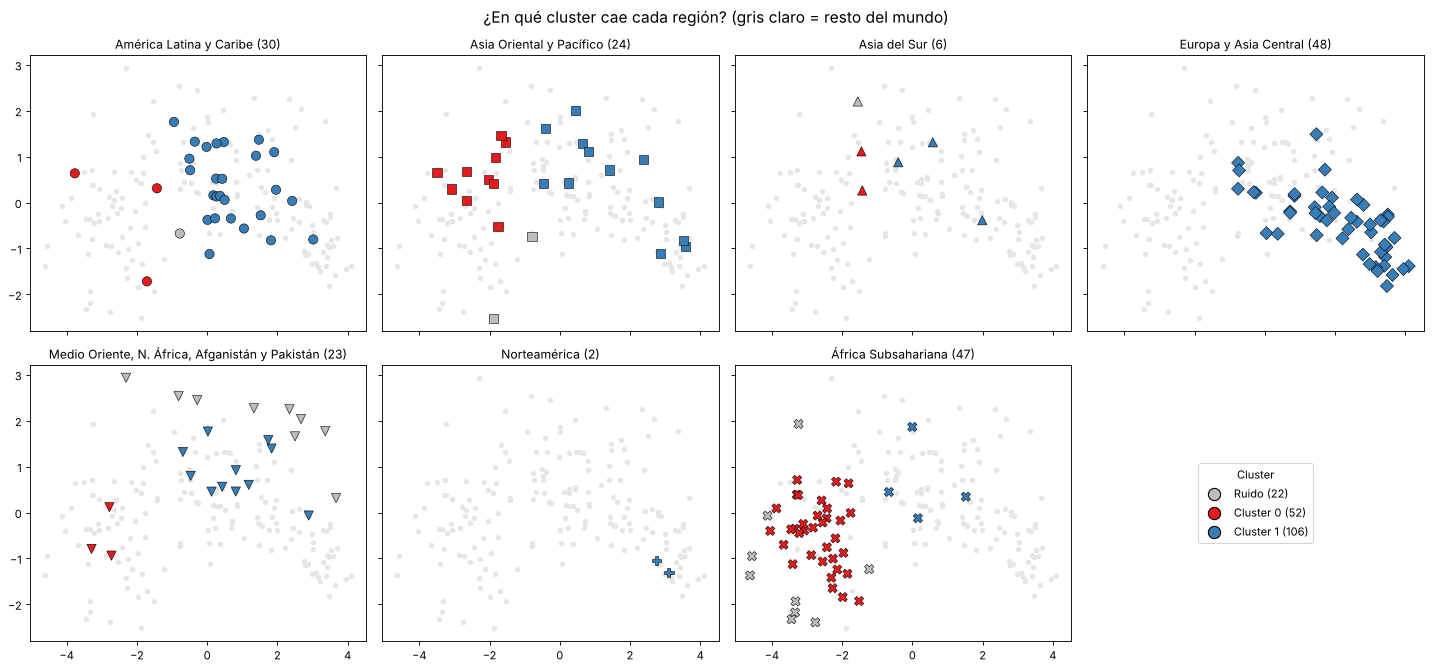

In [26]:
fig, ejes = plt.subplots(2, 4, figsize=(18, 8.5), sharex=True, sharey=True)
ejes = ejes.ravel()
for ax, region in zip(ejes, regiones):
    ax.scatter(mapa["CP1"], mapa["CP2"], color="#e6e6e6", s=15)          # todo el mundo, de fondo
    sub = mapa[mapa["region"] == region]
    ax.scatter(sub["CP1"], sub["CP2"], c=[color_de(c) for c in sub["cluster"]],
               marker=MARCADORES[region], s=70, edgecolor="black", linewidth=0.5)
    ax.set_title(f"{region} ({len(sub)})", fontsize=11)
for ax in ejes[len(regiones):]:
    ax.axis("off")
ejes[-1].legend(handles=leyenda_clusters(mapa), title="Cluster", loc="center")
fig.suptitle("¿En qué cluster cae cada región? (gris claro = resto del mundo)", fontsize=14)
plt.tight_layout()
plt.show()

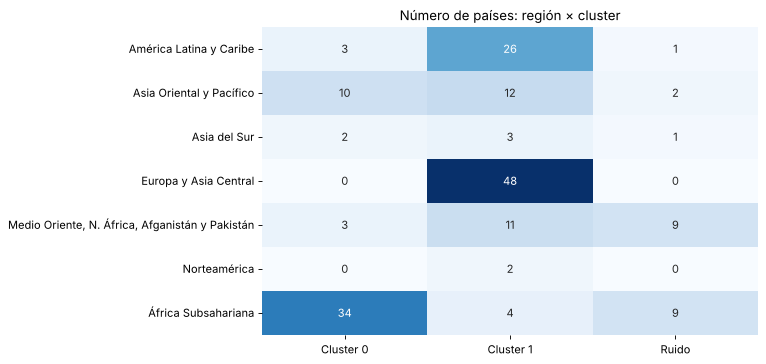

In [27]:
tabla = pd.crosstab(mapa["region"], mapa["grupo"])

plt.figure(figsize=(8, 5))
sns.heatmap(tabla, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Número de países: región × cluster")
plt.xlabel("")
plt.ylabel("")
plt.show()

## 8. Perfil de cada cluster

Promedio de cada indicador (en sus **unidades originales**, sin logaritmo ni escalado) para los países de cada grupo.

In [28]:
perfil = completos[columnas].groupby(mapa["grupo"]).mean()
perfil.insert(0, "Países", mapa["grupo"].value_counts())
perfil.style.background_gradient(cmap="Blues", subset=columnas).format(precision=1)

,Países,Esperanza de vida,Mortalidad <5 años,Mortalidad materna,Gasto en salud (% PIB),Gasto de bolsillo (%),"Médicos x 1,000 hab.",Vacuna DPT (%),"Tuberculosis x 100,000",Muerte por ENT 30-70 (%),Diabetes (%)
grupo,,,,,,,,,,,
Cluster 0,52,66.4,46.8,247.2,5.2,37.0,0.3,77.3,208.5,24.5,7.3
Cluster 1,106,77.5,9.9,28.1,7.5,28.8,3.0,91.1,35.5,15.5,10.2
Ruido,22,70.1,41.9,232.1,5.8,33.8,1.1,82.8,167.5,20.3,12.8


In [29]:
# Países que DBSCAN marcó como ruido (perfiles atípicos)
mapa.loc[mapa["cluster"] == -1, ["pais", "region", "ingreso", "CP1", "CP2"]].sort_values("CP1").round(2)

,pais,region,ingreso,CP1,CP2
iso3,,,,,
CAF,República Centroafricana,África Subsahariana,Bajo,-4.62,-1.37
NGA,Nigeria,África Subsahariana,Medio-bajo,-4.57,-0.95
TCD,Chad,África Subsahariana,Bajo,-4.12,-0.07
SSD,Sudán del Sur,África Subsahariana,Bajo,-3.44,-2.33
LSO,Lesotho,África Subsahariana,Medio-bajo,-3.34,-2.18
ZWE,Zimbabwe,África Subsahariana,Medio-bajo,-3.33,-1.94
SDN,Sudán,África Subsahariana,Bajo,-3.24,1.93
MOZ,Mozambique,África Subsahariana,Bajo,-2.76,-2.39
PAK,Pakistán,"Medio Oriente, N. África, Afganistán y Pakistán",Medio-bajo,-2.31,2.93


In [30]:
# Composición por nivel de ingreso
pd.crosstab(mapa["grupo"], mapa["ingreso"])[["Bajo", "Medio-bajo", "Medio-alto", "Alto"]]

ingreso,Bajo,Medio-bajo,Medio-alto,Alto
grupo,,,,
Cluster 0,17,28,7,0
Cluster 1,0,10,45,51
Ruido,6,8,2,6


## 9. Conclusiones

1. **PCA resumió 10 indicadores en 2 ejes con ~65 % de la información.** El CP1 funciona como un índice de *salud y desarrollo* (esperanza de vida y médicos contra mortalidad y tuberculosis) y el CP2 separa a los países por *diabetes contra gasto en salud*.

2. **DBSCAN (eps = 0.56, min_samples = 5) encontró 2 perfiles y 22 países atípicos:**
   - **Cluster 1 — sistemas de salud consolidados (106 países).** Esperanza de vida de 77.5 años, mortalidad <5 años de 9.9 por mil, 3 médicos por cada 1,000 habitantes y 91 % de vacunación. Incluye a toda Europa y Asia Central, Norteamérica y casi toda América Latina; **México** está aquí. Es un grupo grande porque DBSCAN une a los países de ingreso alto y medio-alto que forman una nube continua.
   - **Cluster 0 — rezago en salud (52 países).** Esperanza de vida de 66.4 años, mortalidad infantil ~5 veces mayor (46.8), mortalidad materna de 247 por 100,000, solo 0.3 médicos por 1,000 y tuberculosis de 208 por 100,000. Lo forman sobre todo países de África Subsahariana (34) e ingreso bajo y medio-bajo.
   - **Ruido (22 países).** No son errores, son perfiles que no se parecen a ningún grupo denso: los países más críticos (República Centroafricana, Nigeria, Chad, Sudán del Sur), los países del Golfo (Qatar, Kuwait, Emiratos, Arabia Saudita) con buena salud general pero diabetes muy alta, y Pakistán, Bangladesh y Egipto, con diabetes alta y mortalidad elevada.

3. **El ingreso explica gran parte de la agrupación,** aunque nunca se usó como variable: el Cluster 0 no tiene ningún país de ingreso alto y el Cluster 1 no tiene ninguno de ingreso bajo.

4. **Limitaciones.** Se descartó *Camas x 1,000 hab.* por baja cobertura y se dejaron fuera 37 territorios con datos incompletos. DBSCAN es sensible a `eps`: un valor menor partiría el Cluster 1 en subgrupos (p. ej. Europa vs. América Latina) y aumentaría el ruido; además, al agrupar sobre 2 componentes se pierde ~35 % de la información.